# Dynamic ORB Strategy
### Utilizing local LLMs
***
This strategy utilizes a *dynamic* opening range system that uses time series to determine which time frame range (1m, 3m, 5m, 15m, 30m, and so on) has the ***highest probability*** of profiting.
This model will also utilize local LLMs (as well as other means of AI & ML) for further decision reasoning.

This model will be utilizing: 
- a volume profile which is used to deterimne which side has/had the most control during that range
- MBO (and aggregated 1m OHLCV) data will be used to identify supply and demand zones for determining where the most likely amount of buying/selling  interest is 
- a 1.25x ATR will be used for calculating the initial stop-loss for risk manage ment (60/40 trailing stop)
- llama3.2:1b for reasoning and advanced decision making (***experimental***)
- NN systems for training the model on high probability ORB ranges
- A time series and monte carlo simulator the test which ORB variation should be used for the given trading session
- a rolling window walk forward analysis backtest to determine viability
***

So far current backtest has yieled **$56,011** with a sharpe of **0.84** on a **2 year long 1m-OHLCV year sample set/size** 

### ***This strategy is meant to be used intradaily with prop-firms having EOD drawdown (Topstep, MFF, Take profit trader, etc)***

# Module.1
### Data/Library importing

In [1]:
"""Cell Block 1"""


import glob
from pathlib import Path
import databento as db
import pandas as pd
import random as rn
import os
import ollama # type: ignore
from collections import defaultdict
import matplotlib.pyplot as plt
import numpy as np
import datetime
import seaborn as sns
import scipy
import sklearn
import statsmodels
import ta # type: ignore
import torch # type: ignore
import torch.nn as nn # type: ignore
import yfinance as yf # type: ignore
import marketwatch as mw # type: ignore

In [2]:
"""Cell Block 2"""


csv_path = Path('/Users/andrew/Kozak Acquisitions/Trading/Data/historical data/NQ/1m OHLCV data/NQ-2010.06.06-2026.01.23-ohlcv-1m.csv.csv')

df_1m = pd.read_csv(
    csv_path,
    dtype={'open': 'float32', 'high': 'float32', 'low': 'float32', 'close': 'float32', 'volume': 'int32', 'instrument_id': 'int32', 'publisher_id': 'int32', 'rtype': 'int32'}
)

# Parse the timestamp column (already in UTC)
df_1m['ts_event'] = pd.to_datetime(df_1m['ts_event'], utc=True)
df_1m.set_index('ts_event', inplace=True)
df_1m.sort_index(inplace=True)

# Show available symbols
print("Unique symbols and counts:")
print(df_1m['symbol'].value_counts().head(20))

print(f"\nLoaded {len(df_1m)} rows, {df_1m.index.min()} to {df_1m.index.max()}")
df_1m.head()

Unique symbols and counts:
symbol
NQZ4    219888
NQZ5    210882
NQU2    210384
NQM2    210297
NQU5    210237
NQZ1    208772
NQM5    208123
NQZ3    207695
NQM4    206573
NQH5    204883
NQU4    204474
NQM3    203936
NQU1    203908
NQM1    201373
NQZ2    201010
NQH2    200626
NQZ0    199937
NQU3    198421
NQH4    197516
NQH1    194528
Name: count, dtype: int64

Loaded 6949239 rows, 2010-06-06 22:00:00+00:00 to 2026-01-23 21:59:00+00:00


,rtype,publisher_id,instrument_id,open,high,low,close,volume,symbol
ts_event,,,,,,,,,
2010-06-06 22:00:00+00:00,33,1,6641,1831.75,1831.75,1828.75,1829.00,117,NQM0
2010-06-06 22:00:00+00:00,33,1,26715,1833.50,1833.50,1827.75,1827.75,3,NQU0
2010-06-06 22:01:00+00:00,33,1,6641,1828.50,1831.00,1828.50,1830.50,99,NQM0
2010-06-06 22:02:00+00:00,33,1,6641,1830.50,1832.25,1830.50,1831.25,32,NQM0
2010-06-06 22:03:00+00:00,33,1,26715,1828.00,1828.00,1828.00,1828.00,1,NQU0


In [3]:
"""Cell Block 3"""


# import MBO data
mbo_folders = [    
    '/Users/andrew/Kozak Acquisitions/Trading/Data/historical data/NQ/MBO data/2025.07.28-2025.10.08',
    '/Users/andrew/Kozak Acquisitions/Trading/Data/historical data/NQ/MBO data/2025.10.10-2025.12-17',
    '/Users/andrew/Kozak Acquisitions/Trading/Data/historical data/NQ/MBO data/2025.12.18-2026.03.08',
    '/Users/andrew/Kozak Acquisitions/Trading/Data/historical data/NQ/MBO data/2026.03.09-2026.05.19'
]

all_zst = []
for folder in mbo_folders:
    folder_path = Path(folder)
    if folder_path.exists():
        # Match DataBento .dbn.zst files
        all_zst.extend(glob.glob(str(folder_path / '*.dbn.zst')))
    else:
        print(f"⚠️  Folder not found: {folder}")

all_zst = sorted(all_zst)
print(f"Found {len(all_zst)} MBO files.")

if not all_zst:
    raise FileNotFoundError("No .dbn.zst files found. Check pattern or paths.")

Found 253 MBO files.


# Module.2a
### Indicators
***
The following indicators the model will use:
- Volume profile proxy with a POC (using aggregated 1m OHLCV & L3 MBO data)
- Delta per minute proxy (using aggregated 1m OHLCV & L3 MBO data)
- 1.25x ATR for risk management

**Volume profile with POC (using MBO data)**


Rebuilt files_by_date
Selected date: 2025-09-26
  Loaded 352,775 NQ trades for 2025-09-26
  Price range: 24520.00 – 24992.00
  POC: 24600.00  (volume: 1,592)
  HVNs: 336 levels | LVNs: 336 levels
  Front-month contract: NQZ5  (1260 bars)


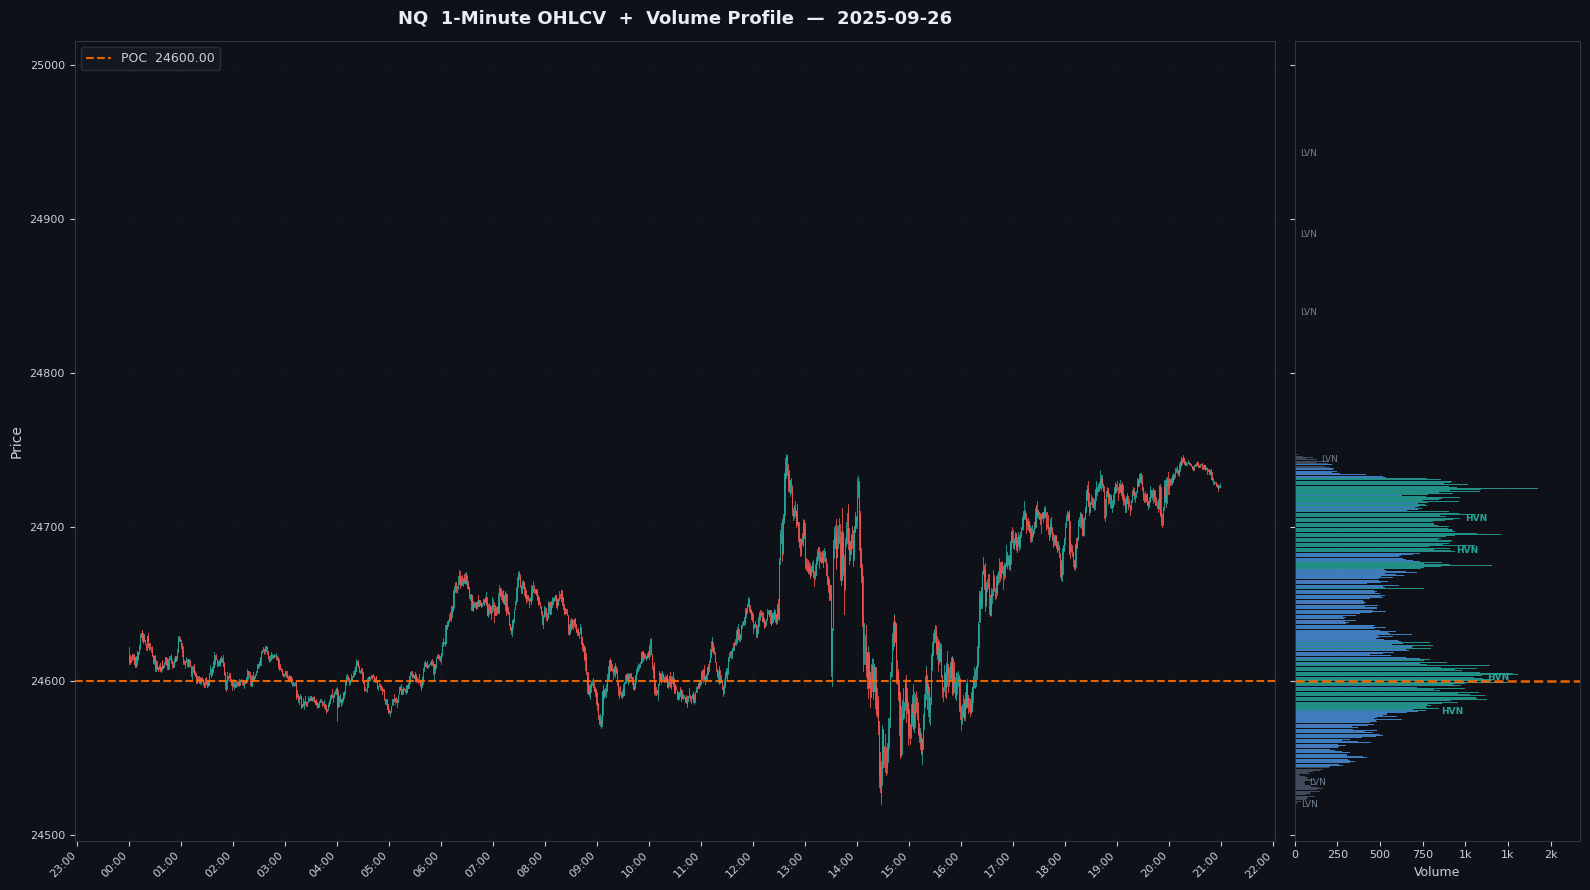

In [4]:
"""Cell Block 1"""


import random
from IPython.core import pylabtools
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
from pathlib import Path
from collections import defaultdict

# ============================================================================
#  VOLUME PROFILE WITH POC  — Using L3 MBO Trade Data
# ============================================================================
# This cell builds a true volume profile from MBO (Market-by-Order) trade
# data, identifies HVNs (High Volume Nodes), LVNs (Low Volume Nodes), and
# the POC (Point of Control), then overlays it on the day's 1-minute OHLCV
# candlestick chart.
#
# Each re-run picks a RANDOM overlapping date between OHLCV and MBO datasets.
# ============================================================================


# ---------- 1. Rebuild files_by_date if not already in memory ----------
if 'files_by_date' not in globals():
    files_by_date = defaultdict(list)
    for f in all_zst:
        name = Path(f).stem
        match = re.search(r'(\d{8})', name)
        if match:
            files_by_date[match.group(1)].append(f)
    print("Rebuilt files_by_date")


# ---------- 2. Pick a random overlapping date ----------
# Filter OHLCV to NQ outright contracts only (exclude spreads like NQU5-NQZ5)
ohlcv_nq = df_1m[df_1m['symbol'].str.match(r'^NQ[A-Z]\d$', na=False)]
ohlc_dates = pd.Series(ohlcv_nq.index.date).unique()
mbo_dates_set = {pd.Timestamp(d).date() for d in files_by_date.keys()}
overlap = sorted([d for d in ohlc_dates if d in mbo_dates_set])

if not overlap:
    raise ValueError("No overlapping dates between OHLCV and MBO data.")

chosen_date = random.choice(overlap)
print(f"Selected date: {chosen_date}")


# ---------- 3. Load MBO trades for that day ----------
# Find matching date key in files_by_date
possible_keys = [k for k in files_by_date if pd.Timestamp(k).date() == chosen_date]
if not possible_keys:
    raise ValueError(f"No MBO files for {chosen_date}")
date_key = possible_keys[0]

frames = []
for f in files_by_date[date_key]:
    store = db.DBNStore.from_file(f)
    frames.append(store.to_df())
day_mbo = pd.concat(frames, ignore_index=True)
day_mbo['ts_event'] = pd.to_datetime(day_mbo['ts_event'], utc=True)

# ── CRITICAL: DataBento to_df() already converts prices to real units ──
# DO NOT divide by 1e9. Prices are already in NQ point values (e.g., 23534.25).

# Filter to NQ outright contracts only (exclude spreads, far-months with
# minimal liquidity). This ensures the volume profile reflects tradeable
# front-month action, not inter-contract noise.
day_mbo = day_mbo[day_mbo['symbol'].str.match(r'^NQ[A-Z]\d$', na=False)]

# Extract executed trades only (action == 'T' is the matched trade message).
# Side semantics for Trade messages (per DataBento docs):
#   'A' = aggressor was a SELLER  (they hit the bid)
#   'B' = aggressor was a BUYER   (they lifted the ask)
#   'N' = no side specified        (rare, exclude)
trades = day_mbo[
    (day_mbo['action'] == 'T') & (day_mbo['side'] != 'N')
][['ts_event', 'side', 'price', 'size']].copy()

print(f"  Loaded {len(trades):,} NQ trades for {chosen_date}")
print(f"  Price range: {trades['price'].min():.2f} – {trades['price'].max():.2f}")


# ---------- 4. Build the volume profile ----------
# Bucket every trade to the nearest NQ tick (0.25 points).
# The profile aggregates total traded size at each price level — this is the
# gaussian-like distribution of volume that reveals where the market spent
# the most time and where it rejected price.
TICK = 0.25
trades['price_bucket'] = (trades['price'] / TICK).round() * TICK
vol_profile = trades.groupby('price_bucket')['size'].sum().sort_index()

# POC: the single price level with the highest traded volume
poc_price = vol_profile.idxmax()
poc_vol   = vol_profile.max()

# HVN / LVN classification via percentile thresholds.
# HVNs (>= 70th pctile) = "acceptance" zones — price was transacted heavily
# LVNs (<= 30th pctile) = "rejection" zones — price moved through quickly
high_thresh = vol_profile.quantile(0.70)
low_thresh  = vol_profile.quantile(0.30)
hvns = vol_profile[vol_profile >= high_thresh]
lvns = vol_profile[vol_profile <= low_thresh]

print(f"  POC: {poc_price:.2f}  (volume: {poc_vol:,})")
print(f"  HVNs: {len(hvns)} levels | LVNs: {len(lvns)} levels")


# ---------- 5. OHLCV for the same day (NQ outrights only) ----------
day_ohlc = ohlcv_nq[ohlcv_nq.index.date == chosen_date].copy().sort_index()

if day_ohlc.empty:
    raise ValueError(f"No OHLCV data found for {chosen_date} after symbol filter.")

# Keeps only the front-month (highest-volume) contract.
front_month = day_ohlc.groupby('symbol')['volume'].sum().idxmax()
day_ohlc = day_ohlc[day_ohlc['symbol'] == front_month]
print(f"  Front-month contract: {front_month}  ({len(day_ohlc)} bars)")


# ---------- 6. High-quality chart ----------
# Layout: 75% candlestick chart | 25% horizontal volume profile
fig = plt.figure(figsize=(16, 9), facecolor='#0e1117')
ax_price = plt.subplot2grid((1, 5), (0, 0), colspan=4)
ax_vol   = plt.subplot2grid((1, 5), (0, 4), sharey=ax_price)

# Style both axes with a dark trading-terminal aesthetic
for ax in [ax_price, ax_vol]:
    ax.set_facecolor('#0e1117')
    ax.tick_params(colors='#c9d1d9', labelsize=8)
    for spine in ax.spines.values():
        spine.set_color('#30363d')

# ── Candlestick chart (manual rendering for full control) ──
# Width of candle bodies in matplotlib date units (fraction of a day).
# For 1-min bars: 1 minute ≈ 1/1440 of a day. We use ~60% of that.
candle_width = (1.0 / 1440) * 0.6
dates_num = mdates.date2num(day_ohlc.index.to_pydatetime())

for d, o, h, l, c in zip(dates_num,
                          day_ohlc['open'], day_ohlc['high'],
                          day_ohlc['low'],  day_ohlc['close']):
    color = '#26a69a' if c >= o else '#ef5350'          # green / red
    body_bottom = min(o, c)
    body_height = abs(c - o) or TICK * 0.1              # prevent zero-height
    # Candle body
    ax_price.add_patch(plt.Rectangle(
        (d - candle_width / 2, body_bottom), candle_width, body_height,
        facecolor=color, edgecolor=color, linewidth=0.5, zorder=2))
    # Wicks
    ax_price.plot([d, d], [l, h], color=color, linewidth=0.6, zorder=1)

ax_price.xaxis_date()
ax_price.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax_price.xaxis.set_major_locator(mdates.HourLocator(interval=1))
plt.setp(ax_price.xaxis.get_majorticklabels(), rotation=45, ha='right')

# POC line across the candlestick panel
ax_price.axhline(y=poc_price, color='#ff6d00', linewidth=1.5, linestyle='--',
                 alpha=0.9, label=f'POC  {poc_price:.2f}', zorder=3)

ax_price.set_ylabel('Price', color='#c9d1d9', fontsize=10)
ax_price.set_title(f'NQ  1-Minute OHLCV  +  Volume Profile  —  {chosen_date}',
                    color='#e6edf3', fontsize=13, fontweight='bold', pad=12)
ax_price.legend(loc='upper left', fontsize=9, facecolor='#161b22',
                edgecolor='#30363d', labelcolor='#c9d1d9')
ax_price.grid(True, alpha=0.15, color='#30363d')

# ── Volume Profile histogram (horizontal bars) ──
# Color each bar: HVN = bright teal, LVN = muted gray, POC = orange, else = steel blue
bar_colors = []
for p in vol_profile.index:
    if p == poc_price:
        bar_colors.append('#ff6d00')       # POC — vivid orange
    elif p in hvns.index:
        bar_colors.append('#26a69a')       # HVN — teal (acceptance)
    elif p in lvns.index:
        bar_colors.append('#4a5568')       # LVN — dim gray (rejection)
    else:
        bar_colors.append('#4a90d9')       # neutral — steel blue

ax_vol.barh(vol_profile.index, vol_profile.values,
            height=TICK * 0.85, color=bar_colors, alpha=0.85,
            edgecolor='none', zorder=2)

# POC line on profile panel
ax_vol.axhline(y=poc_price, color='#ff6d00', linewidth=1.8, linestyle='--',
               alpha=0.9, zorder=3)

# Annotate a sample of HVNs and LVNs
max_vol = vol_profile.max()
for p in hvns.index[::max(1, len(hvns) // 4)]:
    ax_vol.text(vol_profile[p] + max_vol * 0.02, p, 'HVN',
                fontsize=6.5, color='#26a69a', va='center', fontweight='bold')
for p in lvns.index[::max(1, len(lvns) // 6)]:
    ax_vol.text(vol_profile[p] + max_vol * 0.02, p, 'LVN',
                fontsize=6.5, color='#718096', va='center')

ax_vol.set_xlabel('Volume', color='#c9d1d9', fontsize=9)
ax_vol.tick_params(axis='y', labelleft=False)
ax_vol.grid(True, axis='x', alpha=0.1, color='#30363d')
ax_vol.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f'{x/1000:.0f}k' if x >= 1000 else f'{x:.0f}'))

plt.tight_layout()
plt.show()


**Delta bar  analysis (using MBO data)**

Delta Imbalance — selected date: 2025-09-15
  Loaded 291,231 NQ trades for 2025-09-15
  LONG signals: 55 minutes flagged


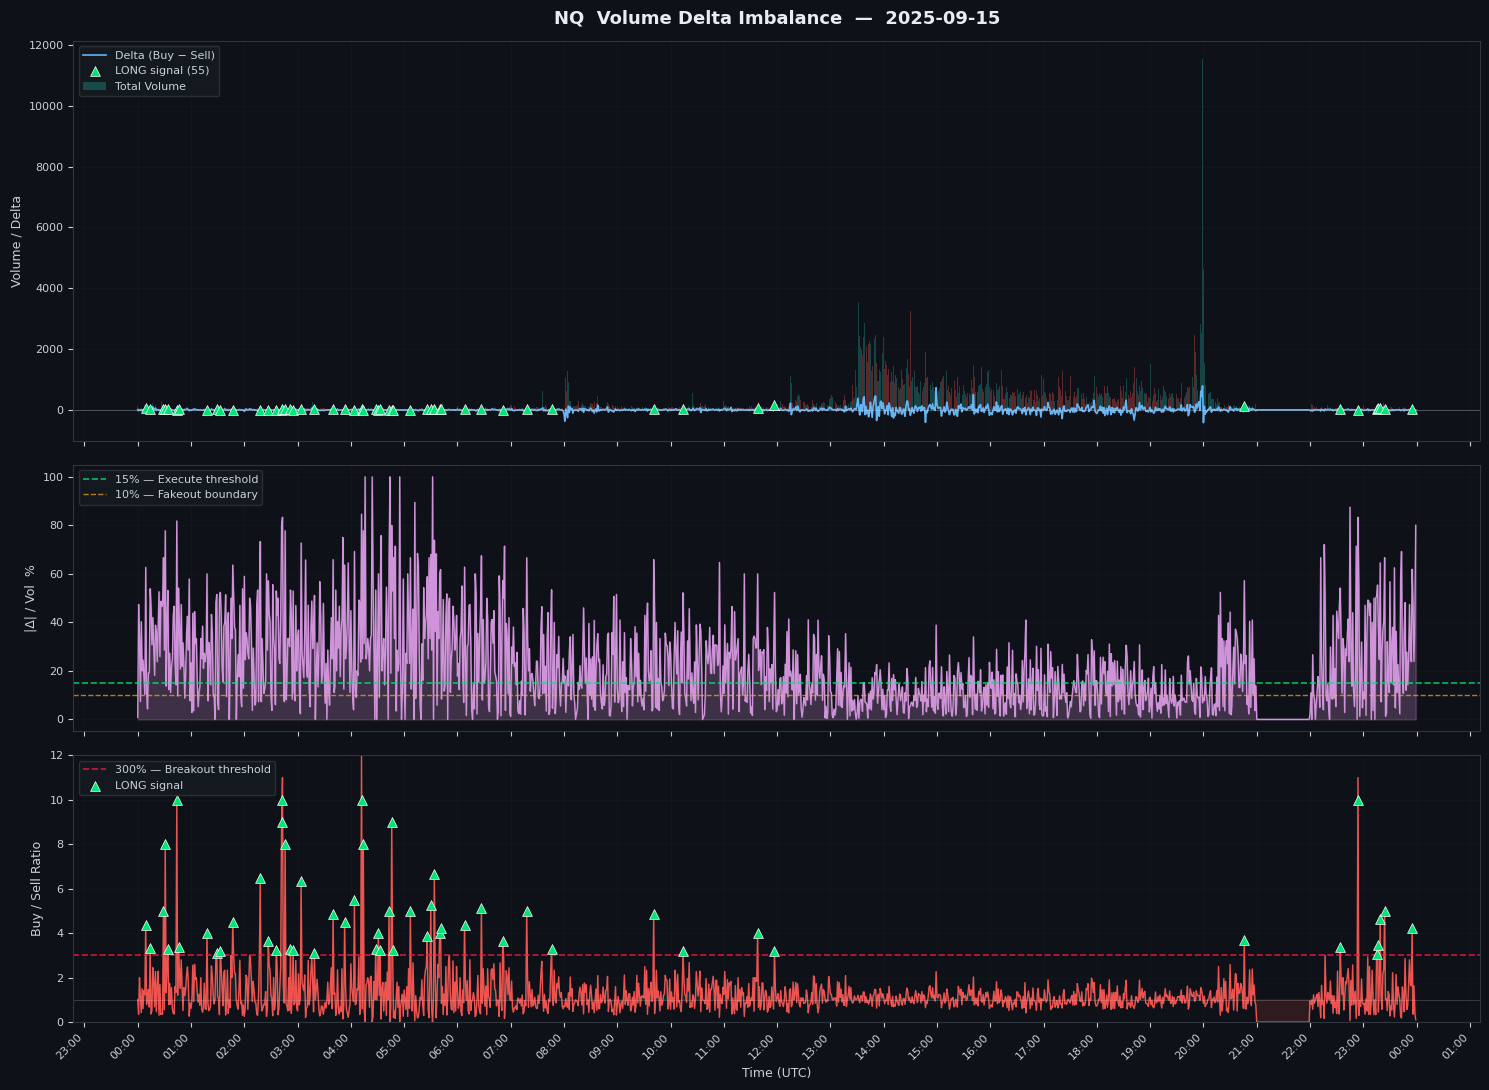

In [5]:
"""Cell Block 2"""


import random
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
from pathlib import Path
from collections import defaultdict

# ============================================================================
#  VOLUME DELTA IMBALANCE  — Using L3 MBO Trade Data
# ============================================================================
# This cell computes per-minute volume delta (buyer aggressor volume minus
# seller aggressor volume) to detect whether a breakout has genuine
# order-flow conviction or is likely a fakeout.
#
# Signal Logic:
#   EXECUTE LONG  → Buy/Sell Ratio > 300%  AND  |Delta|/Volume > 15%
#   IGNORE        → Buy/Sell Ratio < 300%  OR   |Delta|/Volume < 10%
#
# Each re-run picks a RANDOM overlapping date between OHLCV and MBO datasets.
# ============================================================================


# ---------- 1. Rebuild files_by_date if missing ----------
if 'files_by_date' not in globals():
    files_by_date = defaultdict(list)
    for f in all_zst:
        name = Path(f).stem
        match = re.search(r'(\d{8})', name)
        if match:
            files_by_date[match.group(1)].append(f)

# ---------- 2. Random overlapping date ----------
ohlcv_nq = df_1m[df_1m['symbol'].str.match(r'^NQ[A-Z]\d$', na=False)]
ohlc_dates = pd.Series(ohlcv_nq.index.date).unique()
mbo_dates_set = {pd.Timestamp(d).date() for d in files_by_date.keys()}
overlap = sorted([d for d in ohlc_dates if d in mbo_dates_set])

if not overlap:
    raise ValueError("No overlapping dates.")

chosen_date = random.choice(overlap)
print(f"Delta Imbalance — selected date: {chosen_date}")


# ---------- 3. Load MBO trades ----------
date_key = [k for k in files_by_date if pd.Timestamp(k).date() == chosen_date][0]

frames = []
for f in files_by_date[date_key]:
    store = db.DBNStore.from_file(f)
    frames.append(store.to_df())
day_mbo = pd.concat(frames, ignore_index=True)
day_mbo['ts_event'] = pd.to_datetime(day_mbo['ts_event'], utc=True)

# ── CRITICAL: Prices are ALREADY in real NQ points — no division needed ──

# Filter to NQ outright contracts only
day_mbo = day_mbo[day_mbo['symbol'].str.match(r'^NQ[A-Z]\d$', na=False)]

# Extract trades (action == 'T') with valid side attribution
trades = day_mbo[
    (day_mbo['action'] == 'T') & (day_mbo['side'].isin(['A', 'B']))
].copy()

# Floor each trade's timestamp to the nearest minute for aggregation
trades['minute'] = trades['ts_event'].dt.floor('1min')

print(f"  Loaded {len(trades):,} NQ trades for {chosen_date}")


# ---------- 4. Aggregate per minute ----------
# DataBento Trade side semantics:
#   'B' = aggressor was a BUYER  (lifted the ask → bullish pressure)
#   'A' = aggressor was a SELLER (hit the bid    → bearish pressure)
buy_vol  = trades[trades['side'] == 'B'].groupby('minute')['size'].sum()
sell_vol = trades[trades['side'] == 'A'].groupby('minute')['size'].sum()
total_vol = buy_vol.add(sell_vol, fill_value=0)
delta     = buy_vol.sub(sell_vol, fill_value=0)

# |Delta| / Total Volume — measures HOW one-sided the flow is (0–100%)
delta_ratio = (delta.abs() / total_vol.replace(0, np.nan)).fillna(0)

# Buy/Sell Ratio — measures directional dominance (1.0 = balanced)
buy_sell_ratio = (buy_vol / sell_vol.replace(0, np.nan)).fillna(0)
buy_sell_ratio = buy_sell_ratio.replace([np.inf, -np.inf], 10.0)

# Align everything to a uniform 1-minute grid
min_index = pd.date_range(
    start=trades['minute'].min(),
    end=trades['minute'].max(),
    freq='1min'
)
df_m = pd.DataFrame({
    'buy_vol':        buy_vol,
    'sell_vol':       sell_vol,
    'total_vol':      total_vol,
    'delta':          delta,
    'delta_ratio':    delta_ratio,
    'buy_sell_ratio': buy_sell_ratio,
}, index=min_index).fillna(0)


# ---------- 5. Signal logic ----------
# LONG: aggressive buyers dominating (ratio > 3x AND delta conviction > 15%)
long_signal  = (df_m['buy_sell_ratio'] > 3) & (df_m['delta_ratio'] > 0.15)
# IGNORE: either side isn't dominant enough or delta conviction is weak
ignore_signal = (df_m['buy_sell_ratio'] < 3) | (df_m['delta_ratio'] < 0.10)

long_count = long_signal.sum()
print(f"  LONG signals: {long_count} minutes flagged")


# ---------- 6. High-quality 3-panel chart ----------
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(15, 11),
                                     sharex=True, facecolor='#0e1117',
                                     gridspec_kw={'height_ratios': [3, 2, 2]})
for ax in [ax1, ax2, ax3]:
    ax.set_facecolor('#0e1117')
    ax.tick_params(colors='#c9d1d9', labelsize=8)
    for spine in ax.spines.values():
        spine.set_color('#30363d')

# ── Panel 1: Total Volume bars + Delta line ──
# Color each bar by delta direction: green if net buying, red if net selling
bar_colors = ['#26a69a' if d >= 0 else '#ef5350' for d in df_m['delta']]
ax1.bar(df_m.index, df_m['total_vol'], width=pd.Timedelta(seconds=50),
        color=bar_colors, alpha=0.35, label='Total Volume', zorder=1)
ax1.plot(df_m.index, df_m['delta'], color='#64b5f6', linewidth=1.2,
         label='Delta (Buy − Sell)', zorder=2)
ax1.axhline(0, color='#c9d1d9', linewidth=0.6, alpha=0.4)

# Mark LONG signals on the delta line
sig_mask = long_signal & (df_m['delta'] > 0)
if sig_mask.sum() > 0:
    ax1.scatter(df_m.index[sig_mask], df_m['delta'][sig_mask],
                marker='^', color='#00e676', s=50, zorder=3,
                label=f'LONG signal ({long_count})', edgecolors='white',
                linewidths=0.5)

ax1.set_ylabel('Volume / Delta', color='#c9d1d9', fontsize=9)
ax1.legend(loc='upper left', fontsize=8, facecolor='#161b22',
           edgecolor='#30363d', labelcolor='#c9d1d9')
ax1.set_title(f'NQ  Volume Delta Imbalance  —  {chosen_date}',
              color='#e6edf3', fontsize=13, fontweight='bold', pad=12)
ax1.grid(True, alpha=0.12, color='#30363d')

# ── Panel 2: |Delta| / Volume % ──
pct_vals = df_m['delta_ratio'] * 100
ax2.fill_between(df_m.index, pct_vals, alpha=0.25, color='#ce93d8', zorder=1)
ax2.plot(df_m.index, pct_vals, color='#ce93d8', linewidth=1.0, zorder=2)
ax2.axhline(15, color='#00e676', linestyle='--', linewidth=1.2, alpha=0.8,
            label='15% — Execute threshold')
ax2.axhline(10, color='#ffa726', linestyle='--', linewidth=1.0, alpha=0.7,
            label='10% — Fakeout boundary')
ax2.set_ylabel('|Δ| / Vol  %', color='#c9d1d9', fontsize=9)
ax2.legend(loc='upper left', fontsize=8, facecolor='#161b22',
           edgecolor='#30363d', labelcolor='#c9d1d9')
ax2.grid(True, alpha=0.12, color='#30363d')

# ── Panel 3: Buy/Sell Ratio ──
ax3.plot(df_m.index, df_m['buy_sell_ratio'], color='#ef5350', linewidth=1.0)
ax3.fill_between(df_m.index, df_m['buy_sell_ratio'], 1.0,
                 where=df_m['buy_sell_ratio'] > 1.0,
                 alpha=0.15, color='#26a69a', interpolate=True)
ax3.fill_between(df_m.index, df_m['buy_sell_ratio'], 1.0,
                 where=df_m['buy_sell_ratio'] < 1.0,
                 alpha=0.15, color='#ef5350', interpolate=True)
ax3.axhline(3.0, color='#ff1744', linestyle='--', linewidth=1.2, alpha=0.8,
            label='300% — Breakout threshold')
ax3.axhline(1.0, color='#c9d1d9', linewidth=0.5, alpha=0.3)

# Mark LONG signals
if sig_mask.sum() > 0:
    ax3.scatter(df_m.index[sig_mask],
                df_m['buy_sell_ratio'][sig_mask].clip(upper=10),
                marker='^', color='#00e676', s=50, zorder=3,
                label='LONG signal', edgecolors='white', linewidths=0.5)

ax3.set_ylabel('Buy / Sell Ratio', color='#c9d1d9', fontsize=9)
ax3.set_xlabel('Time (UTC)', color='#c9d1d9', fontsize=9)
ax3.set_ylim(0, min(df_m['buy_sell_ratio'].max() * 1.1, 12))
ax3.legend(loc='upper left', fontsize=8, facecolor='#161b22',
           edgecolor='#30363d', labelcolor='#c9d1d9')
ax3.grid(True, alpha=0.12, color='#30363d')

# Format x-axis
ax3.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax3.xaxis.set_major_locator(mdates.HourLocator(interval=1))
plt.setp(ax3.xaxis.get_majorticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.show()


# Module.2b
### Statistical proxies
***
Since we *do not* have long term MBO data, we will need to train a **statistical proxy** that maps OHLCV features to the MBO-derived indicators, using the 8-month overlap as a labeled dataset.
- This gives you a **SEMI**-accurate estimate of volume profile metrics and delta imbalance for a full 16 years.
- This is NOT ground truth but it is better than naive assumptions

### **Volume Profile with POC proxy (for 1‑minute data)**

In [6]:
"""
Cell Block 1 (UPDATED)
Build a daily OHLCV feature matrix (one row per day)
"""

def build_daily_features(df_1m_day):
    """
    Extract daily aggregate features from 1-minute OHLCV bars.
    
    Parameters:
    -----------
    df_1m_day : pd.DataFrame
        OHLCV data for a single trading day (index = datetime)
    
    Returns:
    --------
    dict : Feature dictionary for this day
    
    Notes:
    ------
    - This is a COARSE proxy — daily aggregation loses intraday structure
    - POC is inherently intraday; expect 10-20 handle error on wide-range days
    - Volume binning is vectorized for performance (O(N) vs O(N²))
    """
    o = df_1m_day['open']
    h = df_1m_day['high']
    l = df_1m_day['low']
    c = df_1m_day['close']
    v = df_1m_day['volume']

    features = {}
    
    # ========================================================================
    # PRICE RANGE FEATURES
    # ========================================================================
    features['day_high'] = h.max()
    features['day_low'] = l.min()
    features['day_range'] = features['day_high'] - features['day_low']
    features['day_open'] = o.iloc[0]
    features['day_close'] = c.iloc[-1]
    
    # ========================================================================
    # VOLUME STATISTICS
    # ========================================================================
    features['total_volume'] = v.sum()
    features['volume_std'] = v.std()
    features['volume_skew'] = v.skew()
    
    # ========================================================================
    # VWAP APPROXIMATION
    # ========================================================================
    typical_price = (h + l + c) / 3
    vwap = (typical_price * v).sum() / v.sum() if v.sum() != 0 else typical_price.mean()
    features['vwap_approx'] = vwap

    # ========================================================================
    # CLOSE LOCATION IN RANGE
    # ========================================================================
    # Where did price close relative to the bar's range? (0 = low, 1 = high)
    close_loc = (c - l) / (h - l + 1e-9)
    features['avg_close_loc'] = close_loc.mean()
    features['close_loc_std'] = close_loc.std()

    # ========================================================================
    # VOLUME PROFILE SHAPE PROXY (VECTORIZED)
    # ========================================================================
    # Divide day's range into N bins and compute volume per bin
    # This is a ROUGH approximation of the true volume profile
    
    N_BINS = 20
    day_low = l.min()
    day_high = h.max()
    
    if day_high - day_low < 1e-6:  # Flat day
        bin_volumes = np.zeros(N_BINS)
        bin_volumes[N_BINS // 2] = 1.0  # All volume in middle bin
        bin_centers = np.linspace(day_low, day_high, N_BINS)
    else:
        bin_edges = np.linspace(day_low, day_high, N_BINS + 1)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
        
        # VECTORIZED: Assign each bar's volume to its typical price bin
        bin_indices = np.digitize(typical_price, bin_edges) - 1
        bin_indices = np.clip(bin_indices, 0, N_BINS - 1)
        
        # Accumulate volume per bin
        bin_volumes = np.zeros(N_BINS)
        for i in range(N_BINS):
            bin_volumes[i] = v[bin_indices == i].sum()
        
        # Normalize
        bin_volumes /= bin_volumes.sum() + 1e-9
    
    # Store binned volumes as features
    for i in range(N_BINS):
        features[f'bv_{i}'] = bin_volumes[i]
    
    # Proxy POC from OHLCV alone (as a feature)
    max_bin = np.argmax(bin_volumes)
    features['ohlc_proxy_poc'] = bin_centers[max_bin]

    # ========================================================================
    # INTRADAY VOLATILITY & MOMENTUM
    # ========================================================================
    features['volatility'] = (h - l).mean()
    features['close_open_diff'] = c.iloc[-1] - o.iloc[0]
    features['return_5min'] = (c.iloc[-1] / c.iloc[-6] - 1) if len(c) >= 6 else 0
    
    return features


In [ ]:
"""
Cell Block 2 (FULLY VECTORIZED)
Build training dataset with batch OHLCV feature extraction and batch MBO loading
"""

import re
import pandas as pd
import numpy as np
from collections import defaultdict
from pathlib import Path

# ============================================================================
# BUILD files_by_date & COMPUTE OVERLAP DATES
# ============================================================================
if 'files_by_date' not in globals() or not files_by_date:
    files_by_date = defaultdict(list)
    for f in all_zst:
        fname = Path(f).stem
        match = re.search(r'(\d{8})', fname)
        if match:
            date_str = match.group(1)
            files_by_date[date_str].append(f)
    print(f"✓ Built files_by_date: {len(files_by_date)} unique dates")

# Compute overlap
ohlcv_nq = df_1m[df_1m['symbol'].str.match(r'^NQ[A-Z]\d$', na=False)]
ohlc_dates = set(pd.Series(ohlcv_nq.index.date).unique())
mbo_dates = set(pd.Timestamp(k).date() for k in files_by_date.keys())
overlap_dates = sorted(ohlc_dates & mbo_dates)

if not overlap_dates:
    raise ValueError("No overlapping dates between OHLCV and MBO data!")

print(f"✓ Overlap period: {len(overlap_dates)} days")
print(f"  From: {min(overlap_dates)} to {max(overlap_dates)}")

# ============================================================================
# STEP 1: VECTORIZED OHLCV FEATURE EXTRACTION (all dates at once)
# ============================================================================
print(f"\n[1/3] Extracting OHLCV features...")

# Filter to overlap dates
overlap_mask = pd.Series(ohlcv_nq.index.date).isin(overlap_dates).values
ohlcv_overlap = ohlcv_nq[overlap_mask].copy()

# Batch extract features via groupby
feature_rows = []
feature_dates = []

for date, day_group in ohlcv_overlap.groupby(ohlcv_overlap.index.date):
    feat = build_daily_features(day_group)
    feature_rows.append(feat)
    feature_dates.append(date)

df_feat = pd.DataFrame(feature_rows, index=feature_dates)
print(f"      ✓ Extracted {len(df_feat)} date groups")

# ============================================================================
# STEP 2: BATCH LOAD ALL MBO DATA (once, into memory)
# ============================================================================
print(f"[2/3] Loading {len(overlap_dates)} days of MBO data...")

all_mbo_frames = []
successfully_loaded = []

for idx, date in enumerate(overlap_dates):
    if (idx + 1) % 20 == 0:
        print(f"      Loading {idx+1}/{len(overlap_dates)}...")
    
    date_key = date.strftime('%Y%m%d')
    if date_key not in files_by_date:
        continue
    
    try:
        frames = []
        for f in files_by_date[date_key]:
            store = db.DBNStore.from_file(f)
            frames.append(store.to_df())
        
        day_mbo = pd.concat(frames, ignore_index=True)
        day_mbo['ts_event'] = pd.to_datetime(day_mbo['ts_event'], utc=True)
        day_mbo['date'] = date  # Attach date for later groupby
        all_mbo_frames.append(day_mbo)
        successfully_loaded.append(date)
        
    except Exception as e:
        print(f"      ⚠️  Error loading {date}: {str(e)[:60]}")
        continue

if not all_mbo_frames:
    raise ValueError("No MBO data loaded!")

# Concatenate all at once (faster than appending row-by-row)
all_mbo = pd.concat(all_mbo_frames, ignore_index=True)
print(f"      ✓ Loaded {len(all_mbo):,} total MBO records from {len(successfully_loaded)} days")

# ============================================================================
# STEP 3: VECTORIZED MBO METRIC COMPUTATION (batch groupby)
# ============================================================================
print(f"[3/3] Computing MBO metrics...")

# Filter to NQ outrights only
all_mbo = all_mbo[all_mbo['symbol'].str.match(r'^NQ[A-Z]\d$', na=False)]

# Extract trades (action == 'T') with side attribution
trades = all_mbo[
    (all_mbo['action'] == 'T') & (all_mbo['side'].isin(['A', 'B']))
][['ts_event', 'side', 'price', 'size', 'date']].copy()

# Bucket prices once
TICK = 0.25
trades['price_bucket'] = (trades['price'] / TICK).round() * TICK

# Compute metrics for each date in one pass
target_rows = []
target_dates = []

for date, day_trades in trades.groupby('date'):
    if len(day_trades) == 0:
        continue
    
    # Volume profile
    vol_prof = day_trades.groupby('price_bucket')['size'].sum()
    
    if len(vol_prof) > 0:
        # POC
        poc = vol_prof.idxmax()
        
        # Value Area (15th-85th percentile cumulative volume)
        cumvol = vol_prof.sort_index().cumsum() / vol_prof.sum()
        lower = cumvol[cumvol >= 0.15].index[0] if (cumvol >= 0.15).any() else vol_prof.index.min()
        upper = cumvol[cumvol <= 0.85].index[-1] if (cumvol <= 0.85).any() else vol_prof.index.max()
        
        # Skew
        vol_above = vol_prof[vol_prof.index > poc].sum()
        vol_below = vol_prof[vol_prof.index < poc].sum()
        skew = vol_above / (vol_below + 1e-9)
    else:
        poc, lower, upper, skew = np.nan, np.nan, np.nan, np.nan
    
    target_rows.append({'mbo_poc': poc, 'va_low': lower, 'va_high': upper, 'skew': skew})
    target_dates.append(date)

df_targ = pd.DataFrame(target_rows, index=target_dates)
print(f"      ✓ Computed metrics for {len(df_targ)} dates")

# ============================================================================
# STEP 4: MERGE FEATURES + TARGETS
# ============================================================================
print(f"\n[MERGE] Joining features and targets...")

df_train = df_feat.join(df_targ).dropna(subset=['mbo_poc'])

print(f"\n✓ Training dataset built: {len(df_train)} samples")
print(f"  Features: {len([c for c in df_train.columns if c not in ['mbo_poc', 'va_low', 'va_high', 'skew']])}")
if len(df_train) > 0:
    print(f"  POC range: {df_train['mbo_poc'].min():.2f} - {df_train['mbo_poc'].max():.2f}")
else:
    print("  ⚠️  WARNING: No valid training samples generated!")


✓ Overlap period: 154 days
  From: 2025-07-28 to 2026-01-23

[1/3] Extracting OHLCV features...
      ✓ Extracted 154 date groups
[2/3] Loading 154 days of MBO data...


In [ ]:
"""
Cell Block 3 (UPDATED)
Train the proxy model with validation checks
"""

import xgboost as xgb
from sklearn.metrics import mean_absolute_error
from scipy.stats import ks_2samp

# ============================================================================
# PREPARE TRAINING DATA
# ============================================================================
# Sort by date (chronological split)
df_train = df_train.sort_index()

# Split: 80% train, 20% validation
split_idx = int(0.8 * len(df_train))
train = df_train.iloc[:split_idx]
val = df_train.iloc[split_idx:]

print(f"Train period: {train.index.min()} to {train.index.max()} ({len(train)} days)")
print(f"Val period: {val.index.min()} to {val.index.max()} ({len(val)} days)")

# ============================================================================
# CHECK FOR DISTRIBUTION SHIFT
# ============================================================================
stat, pval = ks_2samp(train['mbo_poc'], val['mbo_poc'])
if pval < 0.05:
    print(f"⚠️  WARNING: Train/val POC distributions differ significantly (p={pval:.4f})")
    print("   This may indicate regime change or data quality issues")
else:
    print(f"✓ Train/val distributions are similar (p={pval:.4f})")

# ============================================================================
# DEFINE FEATURES AND TARGET
# ============================================================================
feature_cols = [c for c in df_train.columns if c not in ['mbo_poc', 'va_low', 'va_high', 'skew']]
X_train = train[feature_cols]
y_train = train['mbo_poc']
X_val = val[feature_cols]
y_val = val['mbo_poc']

print(f"\nFeatures: {len(feature_cols)}")

# ============================================================================
# TRAIN XGBOOST MODEL
# ============================================================================
model_poc = xgb.XGBRegressor(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

print("\nTraining XGBoost model...")
model_poc.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=False
)

# ============================================================================
# EVALUATE
# ============================================================================
y_train_pred = model_poc.predict(X_train)
y_val_pred = model_poc.predict(X_val)

train_mae = mean_absolute_error(y_train, y_train_pred)
val_mae = mean_absolute_error(y_val, y_val_pred)

print(f"\n✓ Model trained")
print(f"  Train MAE: {train_mae:.2f} points")
print(f"  Val MAE: {val_mae:.2f} points")

if val_mae > 2 * train_mae:
    print("  ⚠️  WARNING: Validation error >> training error (overfitting)")

# ============================================================================
# FEATURE IMPORTANCE
# ============================================================================
importances = pd.Series(model_poc.feature_importances_, index=feature_cols).sort_values(ascending=False)
print("\nTop 10 most important features:")
print(importances.head(10))


NameError: name 'df_train' is not defined

In [ ]:
"""
Cell Block 3.5 (NEW)
Build files_by_date mapping and compute overlap dates
"""

# ============================================================================
# BUILD files_by_date DICTIONARY
# ============================================================================
# Maps each date to its corresponding MBO file(s)
# This is required for training the proxy models

files_by_date = defaultdict(list)

for f in all_zst:
    # Extract date from DataBento filename
    # Expected format: glbx-mdp3-YYYYMMDD.mbo.dbn.zst
    fname = Path(f).stem  # Remove .zst extension
    
    # Parse date from filename
    # Split by '-' and take the third element (date part)
    parts = fname.split('-')
    if len(parts) >= 3:
        date_str = parts[2].split('.')[0]  # Extract YYYYMMDD
        try:
            date_obj = pd.to_datetime(date_str, format='%Y%m%d')
            files_by_date[date_obj].append(f)
        except ValueError:
            print(f"⚠️  Could not parse date from filename: {fname}")
            continue

print(f"✓ Built files_by_date: {len(files_by_date)} unique dates")
print(f"  Date range: {min(files_by_date.keys())} to {max(files_by_date.keys())}")

# ============================================================================
# COMPUTE OVERLAP DATES
# ============================================================================
# Find dates present in BOTH MBO and OHLCV datasets

mbo_dates = set(d.date() for d in files_by_date.keys())
ohlcv_dates = set(df_1m.index.date)

overlap_dates = sorted(mbo_dates & ohlcv_dates)

print(f"\n✓ Overlap period: {len(overlap_dates)} days")
if overlap_dates:
    print(f"  From: {min(overlap_dates)}")
    print(f"  To: {max(overlap_dates)}")
else:
    print("  ⚠️  WARNING: No overlapping dates found!")
    print(f"     MBO range: {min(mbo_dates)} to {max(mbo_dates)}")
    print(f"     OHLCV range: {min(ohlcv_dates)} to {max(ohlcv_dates)}")


In [ ]:
"""
Cell Block 4 (UPDATED)
Apply proxy to the full 16-year dataset
"""

# ============================================================================
# APPLY PROXY MODEL TO ALL DATES
# ============================================================================
print("Applying proxy POC to full 16-year dataset...")

def get_proxy_poc_for_day(day_date, model, df_1m_full):
    """
    Predict POC for a single day using the trained model.
    
    Returns:
    --------
    float : Predicted POC price level
    """
    mask = df_1m_full.index.date == day_date
    day_ohlc = df_1m_full[mask]
    
    if day_ohlc.empty:
        return np.nan
    
    # Extract features
    feat = build_daily_features(day_ohlc)
    feat_df = pd.DataFrame([feat])[feature_cols]
    
    # Predict
    poc_pred = model.predict(feat_df)[0]
    return poc_pred

# Get unique dates in full dataset
unique_dates = pd.Series(df_1m.index.date).unique()
proxy_poc_series = pd.Series(index=unique_dates, dtype=float)

print(f"Processing {len(unique_dates)} unique dates...")
for idx, d in enumerate(unique_dates):
    if (idx + 1) % 500 == 0:
        print(f"  {idx+1}/{len(unique_dates)} dates processed")
    
    proxy_poc_series[d] = get_proxy_poc_for_day(d, model_poc, df_1m)

# ============================================================================
# ATTACH TO MAIN DATAFRAME
# ============================================================================
# NOTE: This creates a CONSTANT column within each day
# The proxy POC is a DAILY estimate, not intraday
df_1m['date'] = df_1m.index.date
df_1m['proxy_poc'] = df_1m['date'].map(proxy_poc_series)

print(f"\n✓ Proxy POC applied to {len(df_1m)} rows")
print(f"  Non-null values: {df_1m['proxy_poc'].notna().sum()}")
print(f"  POC range: {df_1m['proxy_poc'].min():.2f} - {df_1m['proxy_poc'].max():.2f}")
print("\n⚠️  IMPORTANT: proxy_poc is a DAILY estimate (constant within each day)")
print("   For intraday precision, consider building a 5-min or 15-min proxy instead")


In [ ]:
"""
Cell Block 5
Sanity check
"""


sample_days = random.sample(list(df_train.index[split_idx:]), 5)
for d in sample_days:
    mask = df_1m.index.date == d
    plt.figure()
    plt.plot(df_1m[mask].index, df_1m[mask]['close'], label='Price')
    # Overlay proxy POC and true POC if available
    true_poc = df_train.loc[d, 'mbo_poc']
    proxy = get_proxy_poc_for_day(d, model_poc, df_1m)
    plt.axhline(true_poc, color='red', label='True POC')
    plt.axhline(proxy, color='blue', linestyle='--', label='Proxy POC')
    plt.legend()
    plt.title(str(d))
    plt.show()

### **Delta per minute bar proxy (for 1‑minute data)**

In [ ]:
"""
Cell Block 6
Build per‑minute OHLCV features
"""


def build_minute_features(df_1m_minute, history_window=5):
    """
    df_1m_minute: a slice of your OHLCV DataFrame containing the current minute + history.
    Returns a dict of features for the LAST minute in the slice.
    """
    o = df_1m_minute['open']
    h = df_1m_minute['high']
    l = df_1m_minute['low']
    c = df_1m_minute['close']
    v = df_1m_minute['volume']

    # The bar we want to predict is the last one
    # Bar-level features
    bar_open = o.iloc[-1]
    bar_high = h.iloc[-1]
    bar_low = l.iloc[-1]
    bar_close = c.iloc[-1]
    bar_volume = v.iloc[-1]
    bar_range = bar_high - bar_low
    bar_close_loc = (bar_close - bar_low) / (bar_range + 1e-9)  # 0-1
    bar_typical_price = (bar_high + bar_low + bar_close) / 3
    bar_return = (bar_close / o.iloc[-1]) - 1  # intra-bar return

    features = {
        'bar_open': bar_open,
        'bar_high': bar_high,
        'bar_low': bar_low,
        'bar_close': bar_close,
        'bar_range': bar_range,
        'bar_close_loc': bar_close_loc,
        'bar_volume': bar_volume,
        'bar_return': bar_return,
    }

    # Rolling window features (last N bars, excluding current)
    if len(df_1m_minute) > 1:
        prev = df_1m_minute.iloc[:-1]
        features['vol_mean_5'] = prev['volume'].tail(history_window).mean()
        features['vol_std_5'] = prev['volume'].tail(history_window).std()
        features['range_mean_5'] = (prev['high'] - prev['low']).tail(history_window).mean()
        features['ret_mean_5'] = prev['close'].pct_change().tail(history_window).mean()
        features['close_loc_mean_5'] = ((prev['close'] - prev['low']) / (prev['high'] - prev['low'] + 1e-9)).tail(history_window).mean()
    else:
        # First bar of the day
        for col in ['vol_mean_5','vol_std_5','range_mean_5','ret_mean_5','close_loc_mean_5']:
            features[col] = np.nan

    # Time-of-day (minute from open)
    features['minute_of_day'] = df_1m_minute.index[-1].hour * 60 + df_1m_minute.index[-1].minute

    return features

In [ ]:
"""
Cellblock.7
Build the training dataset (overlap period)
"""


feature_rows = []
target_rows = []

for d in overlap_dates:
    # OHLCV day
    day_ohlc = df_1m[df_1m.index.date == d].copy()
    # MBO day (re-use same loader as before)
    date_key = [k for k in files_by_date if pd.Timestamp(k).date() == d][0]
    day_mbo = load_mbo_day(date_key)  # you'll wrap your load code into a function
    trades = day_mbo[day_mbo['action'] == 'T'].copy()
    trades['minute'] = trades['ts_event'].dt.floor('1min')
    buy_vol = trades[trades['side'] == 'A'].groupby('minute')['size'].sum()
    sell_vol = trades[trades['side'] == 'B'].groupby('minute')['size'].sum()
    total_vol = buy_vol.add(sell_vol, fill_value=0)
    delta = buy_vol.sub(sell_vol, fill_value=0)
    delta_ratio = (delta.abs() / total_vol.replace(0, np.nan)).fillna(0)
    buy_sell_ratio = (buy_vol / sell_vol.replace(0, np.nan)).fillna(0).replace([np.inf, -np.inf], 10)

    # Align OHLCV minutes with MBO minutes
    common_minutes = day_ohlc.index.intersection(trades['minute'].unique())
    for minute in common_minutes:
        # Get a window of OHLCV up to this minute
        ohlc_window = day_ohlc.loc[:minute].tail(6)  # current minute + up to 5 previous
        feats = build_minute_features(ohlc_window)
        # targets
        tgt = {
            'delta_ratio': delta_ratio.get(minute, 0),
            'buy_sell_ratio': buy_sell_ratio.get(minute, 0),
            'total_vol': total_vol.get(minute, 0),
        }
        feature_rows.append(feats)
        target_rows.append(tgt)

df_X = pd.DataFrame(feature_rows)
df_y = pd.DataFrame(target_rows)

# Drop rows with NaN features (first bars of day)
mask = df_X.notna().all(axis=1)
df_X = df_X[mask]
df_y = df_y[mask]
print(f"Training samples: {len(df_X)}")

In [ ]:
"""
Cellblock.8
Train the proxy model (XGBoost regression)
"""


import xgboost as xgb
from sklearn.metrics import mean_absolute_error

# We need to assign each row a date for splitting
# (We'll add the date during the loop above; here assume we have a 'date' column)
# If not, rebuild with date column. Let's assume df_X has an index that is datetime or you add a date column.
# For simplicity, we'll create a date series:
dates_series = pd.Series([d for d in overlap_dates for _ in range(...)])  # but easier to do in loop.
# In the loop above, add a 'date' column to feature_rows:
# feats['date'] = d
# Then df_X['date'] = ... and we can split.
# So modify: feats['date'] = d in the loop.

# Split chronologically by unique dates
unique_dates = sorted(df_X['date'].unique())
split_date = unique_dates[int(0.8 * len(unique_dates))]
train_mask = df_X['date'] < split_date
val_mask = df_X['date'] >= split_date

X_train = df_X[train_mask].drop(columns=['date'])
y_train_delta = df_y.loc[train_mask, 'delta_ratio']
y_train_ratio = df_y.loc[train_mask, 'buy_sell_ratio']

X_val = df_X[val_mask].drop(columns=['date'])
y_val_delta = df_y.loc[val_mask, 'delta_ratio']
y_val_ratio = df_y.loc[val_mask, 'buy_sell_ratio']

# Model for delta_ratio
model_delta = xgb.XGBRegressor(n_estimators=100, max_depth=5, learning_rate=0.05, random_state=42)
model_delta.fit(X_train, y_train_delta)
pred_delta = model_delta.predict(X_val)
mae_delta = mean_absolute_error(y_val_delta, pred_delta)
print(f"Delta ratio MAE: {mae_delta:.4f}")

# Model for buy_sell_ratio
model_ratio = xgb.XGBRegressor(n_estimators=100, max_depth=5, learning_rate=0.05, random_state=42)
model_ratio.fit(X_train, y_train_ratio)
pred_ratio = model_ratio.predict(X_val)
mae_ratio = mean_absolute_error(y_val_ratio, pred_ratio)
print(f"Buy/Sell ratio MAE: {mae_ratio:.4f}")

# Signal classification accuracy (using thresholds)
true_signal = (y_val_ratio > 3) & (y_val_delta > 0.15)
pred_signal = (pred_ratio > 3) & (pred_delta > 0.15)
from sklearn.metrics import classification_report
print(classification_report(true_signal, pred_signal, target_names=['no signal','LONG']))

In [ ]:
"""
Cellblock.9
Apply proxy to the full 16-year OHLCV data 
with a vectorized batch prediction approach
"""


def build_all_minute_features(df_1m_day):
    # Vectorized feature extraction for a single day
    df = df_1m_day.copy()
    df['bar_range'] = df['high'] - df['low']
    df['close_loc'] = (df['close'] - df['low']) / (df['bar_range'] + 1e-9)
    df['return'] = df['close'] / df['open'] - 1
    df['vol_mean_5'] = df['volume'].rolling(6).apply(lambda x: x.iloc[:-1].mean()) # tricky, better use shift
    # Simpler: use shift
    df['prev_vol_1'] = df['volume'].shift(1)
    # etc. We'll define a full function.
    return df  # with all feature columns

In [ ]:
"""
Cellblock.10
Sanity check
"""


sample_date = validation_dates[0]
day_mask = df_X['date'] == sample_date
X_sample = df_X[day_mask].drop(columns=['date'])
y_true_delta = df_y.loc[day_mask, 'delta_ratio']
pred_delta = model_delta.predict(X_sample)

plt.figure()
plt.plot(y_true_delta.values, label='True delta_ratio')
plt.plot(pred_delta, label='Proxy delta_ratio', linestyle='--')
plt.legend()
plt.show()

### **1.25x ATR (for risk management)**

# Module.3
### Strategy logic
***
This module will contain multiple cellblocks of multiple variations of the opening range breakout.
- The reason for this is to compare each variation to see which one has the most predictive power
- The variations will be assigned a weight (later in this program) based off the performance of each variation